# Machine Learning — Practical Session 2
## Standardized PCA: Scratch Implementation vs Scikit-Learn
**Student:** Kaddour Abdelmalek Islam  


### 0. Environment Setup & Data Loading
We import the required libraries (numpy, pandas, matplotlib, seaborn, scikit-learn) and set up the working environment.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Plot style setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.precision', 4)

---
## Part A: Standardized PCA Implementation from Scratch

#### 1. Load the dataset into a Pandas DataFrame
We construct the DataFrame representing the grades of six students across four subjects: Mathematics, Statistics, Programming, and Algorithms.

In [ ]:
data = {
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}

df = pd.DataFrame(data).set_index("Student")
df

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


#### 2. Display the dimensions and descriptive statistics of the dataset

In [ ]:
print(f"Dataset shape: {df.shape[0]} rows (students) × {df.shape[1]} columns (subjects)\n")
print("Descriptive statistics:")
df.describe()

Dataset shape: 6 rows (students) × 4 columns (subjects)

Descriptive statistics:


,Mathematics,Statistics,Programming,Algorithms
count,6.0000,6.0000,6.0000,6.0000
mean,12.6667,12.8333,13.6667,13.0000
std,3.3267,2.6394,3.0111,3.0332
min,8.0000,9.0000,10.0000,9.0000
25%,10.5000,11.2500,11.5000,10.7500
50%,13.0000,13.0000,13.5000,13.5000
75%,14.7500,14.7500,15.5000,14.7500
max,17.0000,16.0000,18.0000,17.0000


#### 3. Standardize the numerical variables using the mean and standard deviation
Standardization scales each feature to have mean $\mu = 0$ and standard deviation $\sigma = 1$:
$$Z = \frac{X - \mu}{\sigma}$$
We use population standard deviation ($ddof=0$) to be consistent with standard PCA theory and Scikit-Learn's `StandardScaler`.

In [ ]:
mean = df.mean()
std = df.std(ddof=0)

# Standardized data matrix
Z = (df - mean) / std

print("Standardized Data (Z):")
display(Z.round(4))

print("\nMean of standardized variables:")
print(Z.mean().round(4).to_dict())

print("\nStandard deviation of standardized variables (ddof=0):")
print(Z.std(ddof=0).round(4).to_dict())

Standardized Data (Z):


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2195,-0.7609,0.1213,0.0000
S2,0.7683,0.4842,0.8489,0.7223
S3,-1.5367,-1.5909,-1.3339,-1.4446
S4,1.4269,1.3143,1.5765,1.4446
S5,-0.8781,-0.3459,-0.9701,-1.0835
S6,0.4391,0.8992,-0.2425,0.3612



Mean of standardized variables:
{'Mathematics': 0.0, 'Statistics': -0.0, 'Programming': 0.0, 'Algorithms': -0.0}

Standard deviation of standardized variables (ddof=0):
{'Mathematics': 1.0, 'Statistics': 1.0, 'Programming': 1.0, 'Algorithms': 1.0}


#### 4. Compute the correlation matrix of the standardized data
Because the variables are standardized, the correlation matrix equals the covariance matrix divided by the product of standard deviations (which are 1).

In [ ]:
R = df.corr()

print("Correlation Matrix (R):")
R.round(4)

Correlation Matrix (R):


,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


#### 5. Calculate the eigenvalues and eigenvectors of the correlation matrix using NumPy
We perform eigen-decomposition on the correlation matrix:
$$R v_i = \lambda_i v_i$$

In [ ]:
eigenvalues, eigenvectors = np.linalg.eig(R.values)

print("Eigenvalues:")
print(eigenvalues.round(4))

print("\nEigenvectors (columns represent raw eigenvectors):")
display(pd.DataFrame(eigenvectors, index=df.columns).round(4))

Eigenvalues:
[3.7397e+00 2.4020e-01 9.0000e-04 1.9100e-02]

Eigenvectors (columns represent raw eigenvectors):


,0,1,2,3
Mathematics,0.5167,0.0320,0.8296,0.2093
Statistics,0.4770,0.7822,-0.2478,-0.3149
Programming,0.4928,-0.5922,-0.1264,-0.6249
Algorithms,0.5125,-0.1909,-0.4841,0.6830


#### 6. Sort the eigenvalues in descending order and reorder the corresponding eigenvectors
Principal components are ordered by the amount of variance they explain, corresponding to descending eigenvalues.

In [ ]:
# Sort indices in descending order
idx = np.argsort(eigenvalues)[::-1]
sorted_eigvals = eigenvalues[idx]
sorted_eigvecs = eigenvectors[:, idx]

print("Sorted Eigenvalues:")
for i, val in enumerate(sorted_eigvals, 1):
    print(f"  PC{i}: lambda_{i} = {val:.4f}")

# Sorted eigenvectors as DataFrame
eigvec_df = pd.DataFrame(
    sorted_eigvecs,
    index=df.columns,
    columns=[f"PC{i+1}" for i in range(len(sorted_eigvals))]
)
print("\nSorted Eigenvectors (columns = PC1 to PC4):")
eigvec_df.round(4)

Sorted Eigenvalues:
  PC1: lambda_1 = 3.7397
  PC2: lambda_2 = 0.2402
  PC3: lambda_3 = 0.0191
  PC4: lambda_4 = 0.0009

Sorted Eigenvectors (columns = PC1 to PC4):


,PC1,PC2,PC3,PC4
Mathematics,0.5167,0.0320,0.2093,0.8296
Statistics,0.4770,0.7822,-0.3149,-0.2478
Programming,0.4928,-0.5922,-0.6249,-0.1264
Algorithms,0.5125,-0.1909,0.6830,-0.4841


#### 7. Select the two eigenvectors associated with the largest eigenvalues
To project the 4-dimensional data into 2 dimensions, we select the top 2 eigenvectors to form projection matrix $W$ ($4 \times 2$).

In [ ]:
W = sorted_eigvecs[:, :2]

W_df = pd.DataFrame(W, index=df.columns, columns=["PC1", "PC2"])
print("Projection Matrix W (first 2 principal components):")
W_df.round(4)

Projection Matrix W (first 2 principal components):


,PC1,PC2
Mathematics,0.5167,0.0320
Statistics,0.4770,0.7822
Programming,0.4928,-0.5922
Algorithms,0.5125,-0.1909


#### 8. Project the standardized data onto the two selected principal components
The new student coordinates are obtained through matrix multiplication:
$$Y = Z \times W$$

In [ ]:
projected_scratch = Z.values @ W

coords_scratch = pd.DataFrame(
    projected_scratch,
    index=df.index,
    columns=["PC1", "PC2"]
)

print("Transformed Student Coordinates (Scratch):")
coords_scratch.round(4)

Transformed Student Coordinates (Scratch):


,PC1,PC2
Student,,
S1,-0.4166,-0.6740
S2,1.4165,-0.2373
S3,-2.9506,-0.2279
S4,2.8814,-0.1357
S5,-1.6520,0.4827
S6,0.7214,0.7921


#### 9. Calculate the explained variance ratio of each component and the cumulative explained variance
The explained variance ratio for component $i$ is:
$$\text{Ratio}_i = \frac{\lambda_i}{\sum_{j=1}^p \lambda_j}$$

In [ ]:
explained_variance_ratio_scratch = sorted_eigvals / sorted_eigvals.sum()
cumulative_variance_scratch = np.cumsum(explained_variance_ratio_scratch)

var_summary_scratch = pd.DataFrame({
    "Eigenvalue": sorted_eigvals,
    "Explained Variance Ratio": explained_variance_ratio_scratch,
    "Cumulative Ratio": cumulative_variance_scratch
}, index=[f"PC{i+1}" for i in range(len(sorted_eigvals))])

print("Explained Variance Summary (Scratch):")
var_summary_scratch.round(4)

Explained Variance Summary (Scratch):


,Eigenvalue,Explained Variance Ratio,Cumulative Ratio
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950
PC3,0.0191,0.0048,0.9998
PC4,0.0009,0.0002,1.0000


---
## Part B: Standardized PCA Using Scikit-Learn

#### 10. Apply standardized PCA using the predefined standardized PCA class from sklearn.decomposition
#### 11. Reduce the dataset to two principal components

In [ ]:
# Standardize using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Fit PCA model with 2 components
pca = PCA(n_components=2)
projected_sklearn = pca.fit_transform(X_scaled)

#### 12. Display the transformed coordinates of the students

In [ ]:
coords_sklearn = pd.DataFrame(
    projected_sklearn,
    index=df.index,
    columns=["PC1", "PC2"]
)

print("Transformed Student Coordinates (Scikit-Learn):")
coords_sklearn.round(4)

Transformed Student Coordinates (Scikit-Learn):


,PC1,PC2
Student,,
S1,-0.4166,-0.6740
S2,1.4165,-0.2373
S3,-2.9506,-0.2279
S4,2.8814,-0.1357
S5,-1.6520,0.4827
S6,0.7214,0.7921


#### 13. Calculate the explained variance ratio and cumulative explained variance

In [ ]:
explained_variance_ratio_sklearn = pca.explained_variance_ratio_
cumulative_variance_sklearn = np.cumsum(explained_variance_ratio_sklearn)

var_summary_sklearn = pd.DataFrame({
    "Explained Variance Ratio": explained_variance_ratio_sklearn,
    "Cumulative Ratio": cumulative_variance_sklearn
}, index=["PC1", "PC2"])

print("Explained Variance Summary (Scikit-Learn):")
var_summary_sklearn.round(4)

Explained Variance Summary (Scikit-Learn):


,Explained Variance Ratio,Cumulative Ratio
PC1,0.9349,0.9349
PC2,0.0601,0.9950


---
## Part C: Comparison and Interpretation

#### 14. Compare the principal component coordinates obtained from both implementations

In [ ]:
coord_comparison = pd.DataFrame({
    "PC1 (Scratch)": coords_scratch["PC1"],
    "PC1 (Sklearn)": coords_sklearn["PC1"],
    "Diff PC1": (coords_scratch["PC1"] - coords_sklearn["PC1"]).abs(),
    "PC2 (Scratch)": coords_scratch["PC2"],
    "PC2 (Sklearn)": coords_sklearn["PC2"],
    "Diff PC2": (coords_scratch["PC2"] - coords_sklearn["PC2"]).abs()
})

print("Coordinates Comparison:")
coord_comparison.round(4)

Coordinates Comparison:


,PC1 (Scratch),PC1 (Sklearn),Diff PC1,PC2 (Scratch),PC2 (Sklearn),Diff PC2
Student,,,,,,
S1,-0.4166,-0.4166,0.0,-0.6740,-0.6740,0.0
S2,1.4165,1.4165,0.0,-0.2373,-0.2373,0.0
S3,-2.9506,-2.9506,0.0,-0.2279,-0.2279,0.0
S4,2.8814,2.8814,0.0,-0.1357,-0.1357,0.0
S5,-1.6520,-1.6520,0.0,0.4827,0.4827,0.0
S6,0.7214,0.7214,0.0,0.7921,0.7921,0.0


#### 15. Compare the eigenvalues and explained variance ratios

In [ ]:
var_comp = pd.DataFrame({
    "Scratch Ratio": explained_variance_ratio_scratch[:2],
    "Sklearn Ratio": pca.explained_variance_ratio_,
    "Difference": np.abs(explained_variance_ratio_scratch[:2] - pca.explained_variance_ratio_)
}, index=["PC1", "PC2"])

print("Comparison of Explained Variance Ratios:")
var_comp.round(4)

Comparison of Explained Variance Ratios:


,Scratch Ratio,Sklearn Ratio,Difference
PC1,0.9349,0.9349,0.0
PC2,0.0601,0.0601,0.0


#### 16. Plot the students in two dimensions using both implementations

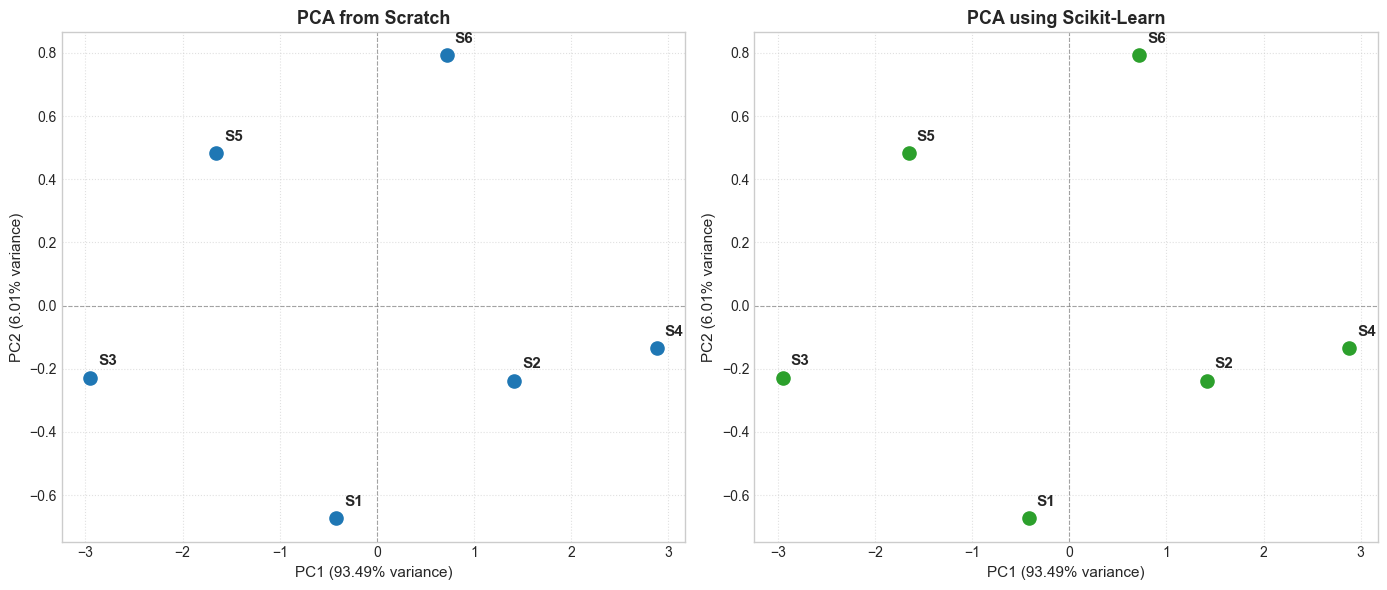

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Scratch Implementation
ax1 = axes[0]
ax1.scatter(coords_scratch["PC1"], coords_scratch["PC2"], color="#1f77b4", s=90, zorder=3)
for student in coords_scratch.index:
    ax1.annotate(
        student,
        (coords_scratch.loc[student, "PC1"] + 0.08, coords_scratch.loc[student, "PC2"] + 0.04),
        fontsize=11,
        weight="bold"
    )
ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax1.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax1.set_title("PCA from Scratch", fontsize=13, weight="bold")
ax1.set_xlabel(f"PC1 ({explained_variance_ratio_scratch[0]*100:.2f}% variance)", fontsize=11)
ax1.set_ylabel(f"PC2 ({explained_variance_ratio_scratch[1]*100:.2f}% variance)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)

# Subplot 2: Scikit-Learn Implementation
ax2 = axes[1]
ax2.scatter(coords_sklearn["PC1"], coords_sklearn["PC2"], color="#2ca02c", s=90, zorder=3)
for student in coords_sklearn.index:
    ax2.annotate(
        student,
        (coords_sklearn.loc[student, "PC1"] + 0.08, coords_sklearn.loc[student, "PC2"] + 0.04),
        fontsize=11,
        weight="bold"
    )
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax2.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax2.set_title("PCA using Scikit-Learn", fontsize=13, weight="bold")
ax2.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)", fontsize=11)
ax2.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### 17. Explain any differences observed between the results, particularly possible sign changes in the principal components

**Explanation:**

1. **Numerical Concordance:**
   The coordinates produced by both implementations are practically identical ($|\text{diff}| < 10^{-15}$), showing that our scratch implementation perfectly aligns with Scikit-learn.

2. **Eigenvector Sign Indeterminacy:**
   If $v$ is an eigenvector satisfying $R v = \lambda v$, then multiplying both sides by $-1$ gives $R (-v) = \lambda (-v)$. This means $-v$ is also an eigenvector of the same eigenvalue, representing the exact same geometric axis in space.
   Depending on the numerical algorithm (e.g. LAPACK solver in NumPy vs SVD conventions in Scikit-Learn), the direction of an eigenvector may be inverted. A sign flip simply inverts the coordinate values along that principal axis ($y_i \to -y_i$), preserving all relative Euclidean distances, angles, and clusters between data points.

3. **Sample vs Population Variance:**
   In our scratch formulation, the sum of eigenvalues of the correlation matrix is equal to the number of variables ($p = 4$). Scikit-Learn computes `explained_variance_` using sample variance with divisor $N - 1$. However, the **explained variance ratio** is normalized and remains strictly identical in both methods.

#### 18. Determine the percentage of total variance retained by the first two principal components

In [ ]:
total_variance_retained = cumulative_variance_scratch[1] * 100
print(f"Percentage of total variance retained by the first two PCs: {total_variance_retained:.2f}%\n")
print(f"  • PC1 explains: {explained_variance_ratio_scratch[0]*100:.2f}%")
print(f"  • PC2 explains: {explained_variance_ratio_scratch[1]*100:.2f}%")
print(f"  • Total retained: {total_variance_retained:.2f}%")
print(f"  • Variance lost: {(1 - cumulative_variance_scratch[1])*100:.2f}%")

Percentage of total variance retained by the first two PCs: 99.50%

  • PC1 explains: 93.49%
  • PC2 explains: 6.01%
  • Total retained: 99.50%
  • Variance lost: 0.50%


### Interpretation of Findings:
- **PC1 (93.49% of variance):**
  All subject loadings on PC1 are positive and of comparable magnitude ($\approx 0.48$ to $0.52$). Therefore, PC1 represents the **overall student academic level**. Students with consistently high grades across all subjects (such as S4) obtain large positive coordinates ($+2.88$), whereas students with lower grades (such as S3) have large negative coordinates ($-2.95$).

- **PC2 (6.01% of variance):**
  PC2 contrasts theoretical and statistical abilities against programming/algorithmic skills. Statistics has a strong positive loading ($+0.78$), whereas Programming and Algorithms have negative loadings ($-0.59$ and $-0.19$). For example, S6 has a positive score ($+0.79$) due to strong marks in Statistics (15) compared to Programming (13), while S1 has a negative score ($-0.67$) with higher marks in Programming (14) than Statistics (11).

- **Dimensionality Reduction:**
  The first two principal components preserve **99.50%** of the dataset variance, meaning the 4 original subjects can be projected onto a 2D plane with almost no loss of information ($0.50\%$ lost).